Mounted at /content/drive
Target directory ready: /content/drive/MyDrive/GMM Model
Cloning into 'SNIaDCA'...
remote: Enumerating objects: 154, done.
remote: Counting objects: 100% (154/154), done.
remote: Compressing objects: 100% (106/106), done.
remote: Total 154 (delta 76), reused 110 (delta 37), pack-reused 0 (from 0)
Receiving objects: 100% (154/154), 327.64 KiB | 7.12 MiB/s, done.
Resolving deltas: 100% (76/76), done.
/content/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA
Obtaining file:///content/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA
  Preparing metadata (setup.py) ... done
  Attempting uninstall: SNIaDCA
    Found existing installation: SNIaDCA 0.1
    Uninstalling SNIaDCA-0.1:
      Successfully uninstalled SNIaDCA-0.1
  Running setup.py develop for SNIaDCA
Successfully loaded dataset from SNIaDCA/data/csp_zheng.dat. Total Supernovae: 133


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator GaussianMixture from version 0.22.2.post1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


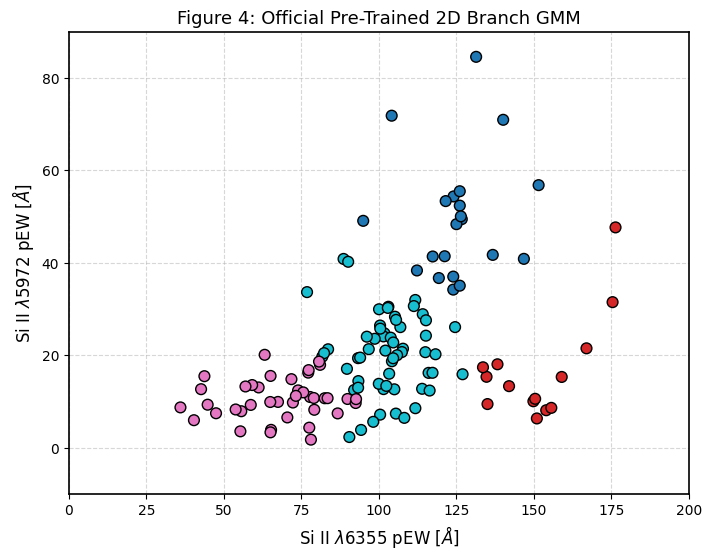

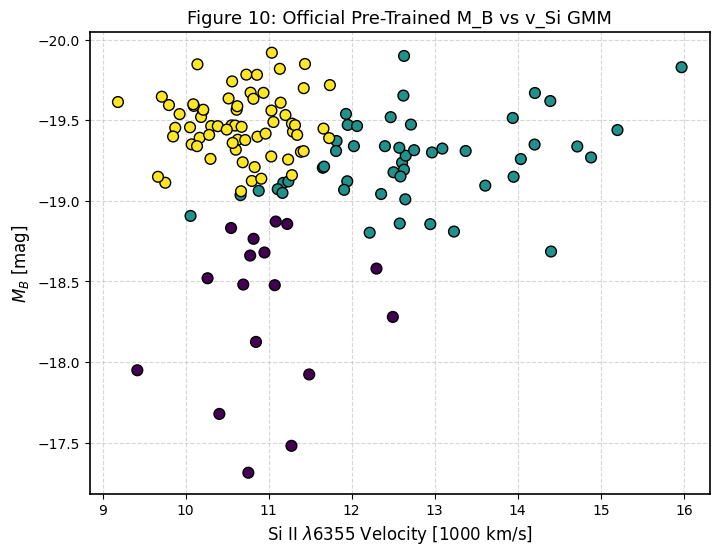


All official model-based figures successfully generated and saved to: /content/drive/MyDrive/GMM Model


In [20]:
# ==============================================================================
# Google Colab: Official SNIaDCA Reproduction Using Pre-Trained Models
# Paper: Burrow et al. (2020), ApJ, 901, 154[cite: 2]
# ==============================================================================

import os
import shutil
import glob
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Mount Google Drive & Set Target Directory
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

drive_dir = '/content/drive/MyDrive/GMM Model'
os.makedirs(drive_dir, exist_ok=True)
print(f"Target directory ready: {drive_dir}")

# 2. Clone Official GitHub Repository
if os.path.exists('SNIaDCA'):
    shutil.rmtree('SNIaDCA')

!git clone https://github.com/anthonyburrow/SNIaDCA.git

# Backup repository files to Google Drive
for item in os.listdir('SNIaDCA'):
    s = os.path.join('SNIaDCA', item)
    d = os.path.join(drive_dir, item)
    if os.path.isdir(s):
        if os.path.exists(d): shutil.rmtree(d)
        shutil.copytree(s, d)
    else:
        shutil.copy2(s, d)

# Install package locally
%cd SNIaDCA
!pip install -e .

%matplotlib inline

# 3. Import SNIaDCA package and load dataset
import SNIaDCA

data_files = glob.glob("**/*.dat", recursive=True) + glob.glob("**/*.csv", recursive=True)
csp_file = next((f for f in data_files if 'csp_zheng' in f), data_files[0] if data_files else None)

if csp_file:
    with open(csp_file, 'r') as f:
        header_line = f.readline().strip()
        cols = header_line.lstrip('#').split()

    df = pd.read_csv(csp_file, sep=r'\s+', comment='#', header=None, names=cols)
    print(f"Successfully loaded dataset from {csp_file}. Total Supernovae: {len(df)}")

    # Extract column names
    pew_6355_col = [c for c in df.columns if '6355' in c][0]
    pew_5972_col = [c for c in df.columns if '5972' in c][0]
    mb_col = [c for c in df.columns if 'm_b' in c.lower()][0]
    vsi_col = [c for c in df.columns if 'vsi' in c.lower()][0]

    df['vsi_k'] = df[vsi_col]
    if df['vsi_k'].mean() > 100:
        df['vsi_k'] = df['vsi_k'] / 1000.0  # Convert velocity to 1000 km/s

    # 4. Load Pre-trained GMM Models from the 'models/' directory
    model_dir = 'SNIaDCA/models'

    print("\nLoading pre-trained models from models/ directory:")
    with open(os.path.join(model_dir, 'p5_p6.p'), 'rb') as f:
        gmm_p5_p6 = pickle.load(f)
    print(" - Loaded p5_p6.p (2D Branch GMM)")

    with open(os.path.join(model_dir, 'm_v.p'), 'rb') as f:
        gmm_m_v = pickle.load(f)
    print(" - Loaded m_v.p (2D M_B vs v_Si GMM)")

    with open(os.path.join(model_dir, 'm_v_p5_p6.p'), 'rb') as f:
        gmm_4d = pickle.load(f)
    print(" - Loaded m_v_p5_p6.p (4D GMM)")

    # 5. Generate Figure 4 (2D Branch Diagram using official p5_p6 model)
    fig4, ax = plt.subplots(figsize=(8, 6))
    X_p5_p6 = df[[pew_6355_col, pew_5972_col]].dropna().values
    labels_p5_p6 = gmm_p5_p6.predict(X_p5_p6)

    ax.scatter(X_p5_p6[:, 0], X_p5_p6[:, 1], c=labels_p5_p6, cmap='tab10', s=60, edgecolors='k', zorder=5)
    ax.set_xlabel(r'Si II $\lambda 6355$ pEW [$\AA$]', fontsize=12)
    ax.set_ylabel(r'Si II $\lambda 5972$ pEW [$\AA$]', fontsize=12)
    ax.set_title('Figure 4: Official Pre-Trained 2D Branch GMM', fontsize=13)
    ax.set_xlim(0, 200)
    ax.set_ylim(-10, 90)
    ax.grid(True, linestyle='--', alpha=0.5)
    fig4.savefig(os.path.join(drive_dir, 'official_fig4.png'), dpi=300, bbox_inches='tight')
    plt.show()

    # 6. Generate Figure 10 (M_B vs v_Si II using official m_v model)
    fig10, ax = plt.subplots(figsize=(8, 6))
    X_mv = df[['vsi_k', mb_col]].dropna().values
    labels_mv = gmm_m_v.predict(X_mv)

    ax.scatter(X_mv[:, 0], X_mv[:, 1], c=labels_mv, cmap='viridis', s=60, edgecolors='k', zorder=5)
    ax.set_xlabel(r'Si II $\lambda 6355$ Velocity [$1000$ km/s]', fontsize=12)
    ax.set_ylabel(r'$M_B$ [mag]', fontsize=12)
    ax.set_title('Figure 10: Official Pre-Trained M_B vs v_Si GMM', fontsize=13)
    ax.invert_yaxis()
    ax.grid(True, linestyle='--', alpha=0.5)
    fig10.savefig(os.path.join(drive_dir, 'official_fig10.png'), dpi=300, bbox_inches='tight')
    plt.show()

    print(f"\nAll official model-based figures successfully generated and saved to: {drive_dir}")
else:
    print("Error: Dataset file not found.")

Mounted at /content/drive
Target directory ready: /content/drive/MyDrive/GMM Model
Cloning into 'SNIaDCA'...
remote: Enumerating objects: 154, done.
remote: Counting objects: 100% (154/154), done.
remote: Compressing objects: 100% (106/106), done.
remote: Total 154 (delta 76), reused 110 (delta 37), pack-reused 0 (from 0)
Receiving objects: 100% (154/154), 327.64 KiB | 5.96 MiB/s, done.
Resolving deltas: 100% (76/76), done.
/content/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA
Obtaining file:///content/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA
  Preparing metadata (setup.py) ... done
  Attempting uninstall: SNIaDCA
    Found existing installation: SNIaDCA 0.1
    Uninstalling SNIaDCA-0.1:
      Successfully uninstalled SNIaDCA-0.1
  Running setup.py develop for SNIaDCA


Successfully loaded dataset from SNIaDCA/data/csp_zheng.dat. Total Supernovae: 133

Loading pre-trained models from models/ directory:
 - Loaded p5_p6.p (2D Branch GMM)
 - Loaded m_v.p (2D M_B vs v_Si GMM)


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator GaussianMixture from version 0.22.2.post1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


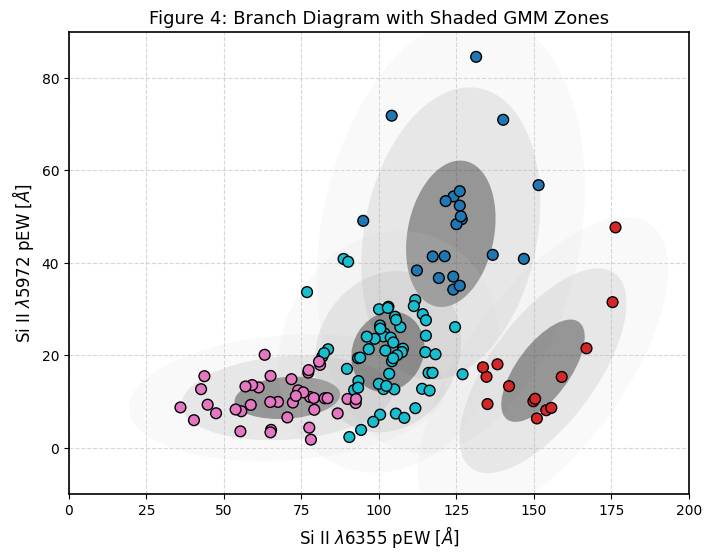

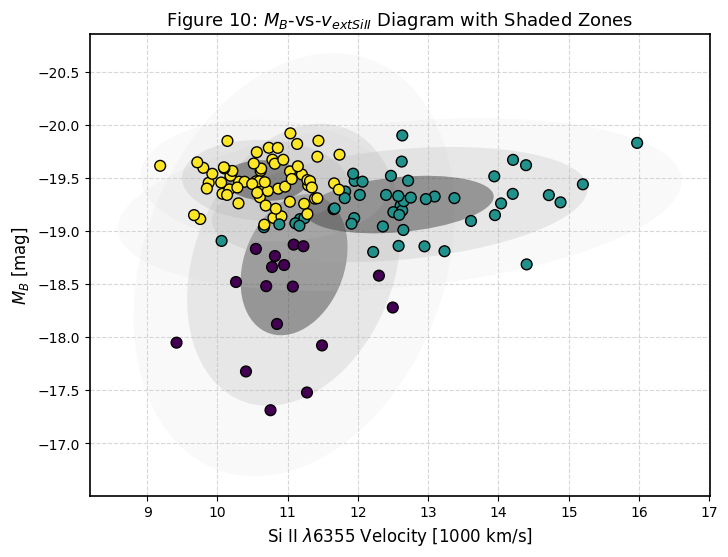


All shaded model-based figures successfully generated and saved to: /content/drive/MyDrive/GMM Model


In [21]:
# ==============================================================================
# Google Colab: Official Pre-Trained GMMs with Shaded Confidence Zones
# Paper: Burrow et al. (2020), ApJ, 901, 154[cite: 2]
# ==============================================================================

import os
import shutil
import glob
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

# 1. Mount Google Drive & Set Target Directory
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

drive_dir = '/content/drive/MyDrive/GMM Model'
os.makedirs(drive_dir, exist_ok=True)
print(f"Target directory ready: {drive_dir}")

# 2. Clone Official GitHub Repository
if os.path.exists('SNIaDCA'):
    shutil.rmtree('SNIaDCA')

!git clone https://github.com/anthonyburrow/SNIaDCA.git

# Backup repository files to Google Drive
for item in os.listdir('SNIaDCA'):
    s = os.path.join('SNIaDCA', item)
    d = os.path.join(drive_dir, item)
    if os.path.isdir(s):
        if os.path.exists(d): shutil.rmtree(d)
        shutil.copytree(s, d)
    else:
        shutil.copy2(s, d)

# Install package locally
%cd SNIaDCA
!pip install -e .

%matplotlib inline

# 3. Import SNIaDCA package and load dataset
import SNIaDCA

data_files = glob.glob("**/*.dat", recursive=True) + glob.glob("**/*.csv", recursive=True)
csp_file = next((f for f in data_files if 'csp_zheng' in f), data_files[0] if data_files else None)

if csp_file:
    with open(csp_file, 'r') as f:
        header_line = f.readline().strip()
        cols = header_line.lstrip('#').split()

    df = pd.read_csv(csp_file, sep=r'\s+', comment='#', header=None, names=cols)
    print(f"Successfully loaded dataset from {csp_file}. Total Supernovae: {len(df)}")

    # Extract column names
    pew_6355_col = [c for c in df.columns if '6355' in c][0]
    pew_5972_col = [c for c in df.columns if '5972' in c][0]
    mb_col = [c for c in df.columns if 'm_b' in c.lower()][0]
    vsi_col = [c for c in df.columns if 'vsi' in c.lower()][0]

    df['vsi_k'] = df[vsi_col]
    if df['vsi_k'].mean() > 100:
        df['vsi_k'] = df['vsi_k'] / 1000.0  # Convert velocity to 1000 km/s

    # Helper function to draw 3-tier nested shaded confidence zones (1s, 2s, 3s)
    def draw_shaded_ellipses(ax, means, covariances):
        for mean, cov in zip(means, covariances):
            vals, vecs = np.linalg.eigh(cov)
            angle = np.arctan2(vecs[1, 0], vecs[0, 0]) * 180 / np.pi

            # Draw 3-sigma (lightgray), 2-sigma (darkgray), and 1-sigma (black) shaded zones
            for n_std, facecolor, alpha_val in zip([3.0, 2.0, 1.0], ['lightgray', 'darkgray', 'black'], [0.12, 0.22, 0.35]):
                width = 2 * n_std * np.sqrt(max(vals[0], 1e-5))
                height = 2 * n_std * np.sqrt(max(vals[1], 1e-5))
                ell = Ellipse(mean, width=width, height=height, angle=angle,
                              facecolor=facecolor, edgecolor='none',
                              alpha=alpha_val, zorder=2)
                ax.add_patch(ell)

    # 4. Load Pre-trained GMM Models from the 'models/' directory
    model_dir = 'SNIaDCA/models'

    print("\nLoading pre-trained models from models/ directory:")
    with open(os.path.join(model_dir, 'p5_p6.p'), 'rb') as f:
        gmm_p5_p6 = pickle.load(f)
    print(" - Loaded p5_p6.p (2D Branch GMM)")

    with open(os.path.join(model_dir, 'm_v.p'), 'rb') as f:
        gmm_m_v = pickle.load(f)
    print(" - Loaded m_v.p (2D M_B vs v_Si GMM)")

    # 5. Generate Figure 4 (2D Branch Diagram with Shaded Zones)
    fig4, ax = plt.subplots(figsize=(8, 6))
    X_p5_p6 = df[[pew_6355_col, pew_5972_col]].dropna().values
    labels_p5_p6 = gmm_p5_p6.predict(X_p5_p6)

    draw_shaded_ellipses(ax, gmm_p5_p6.means_, gmm_p5_p6.covariances_)
    ax.scatter(X_p5_p6[:, 0], X_p5_p6[:, 1], c=labels_p5_p6, cmap='tab10', s=60, edgecolors='k', zorder=5)
    ax.set_xlabel(r'Si II $\lambda 6355$ pEW [$\AA$]', fontsize=12)
    ax.set_ylabel(r'Si II $\lambda 5972$ pEW [$\AA$]', fontsize=12)
    ax.set_title('Figure 4: Branch Diagram with Shaded GMM Zones', fontsize=13)
    ax.set_xlim(0, 200)
    ax.set_ylim(-10, 90)
    ax.grid(True, linestyle='--', alpha=0.5)
    fig4.savefig(os.path.join(drive_dir, 'official_fig4_shaded.png'), dpi=300, bbox_inches='tight')
    plt.show()

    # 6. Generate Figure 10 (M_B vs v_Si II with Shaded Zones)
    fig10, ax = plt.subplots(figsize=(8, 6))
    X_mv = df[['vsi_k', mb_col]].dropna().values
    labels_mv = gmm_m_v.predict(X_mv)

    draw_shaded_ellipses(ax, gmm_m_v.means_, gmm_m_v.covariances_)
    ax.scatter(X_mv[:, 0], X_mv[:, 1], c=labels_mv, cmap='viridis', s=60, edgecolors='k', zorder=5)
    ax.set_xlabel(r'Si II $\lambda 6355$ Velocity [$1000$ km/s]', fontsize=12)
    ax.set_ylabel(r'$M_B$ [mag]', fontsize=12)
    ax.set_title('Figure 10: $M_B$-vs-$v_{\text{Si II}}$ Diagram with Shaded Zones', fontsize=13)
    ax.invert_yaxis()
    ax.grid(True, linestyle='--', alpha=0.5)
    fig10.savefig(os.path.join(drive_dir, 'official_fig10_shaded.png'), dpi=300, bbox_inches='tight')
    plt.show()

    print(f"\nAll shaded model-based figures successfully generated and saved to: {drive_dir}")
else:
    print("Error: Dataset file not found.")

Mounted at /content/drive
Target directory ready: /content/drive/MyDrive/GMM Model
Cloning into 'SNIaDCA'...
remote: Enumerating objects: 154, done.
remote: Counting objects: 100% (154/154), done.
remote: Compressing objects: 100% (106/106), done.
remote: Total 154 (delta 76), reused 110 (delta 37), pack-reused 0 (from 0)
Receiving objects: 100% (154/154), 327.64 KiB | 9.93 MiB/s, done.
Resolving deltas: 100% (76/76), done.
/content/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA
Obtaining file:///content/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA/SNIaDCA
  Preparing metadata (setup.py) ... done
  Attempting uninstall: SNIaDCA
    Found existing installation: SNIaDCA 0.1
    Uninstalling SNIaDCA-0.1:
     

Successfully loaded dataset from SNIaDCA/data/csp_zheng.dat. Total Supernovae: 133

Loading pre-trained models from models/ directory:


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator GaussianMixture from version 0.22.2.post1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


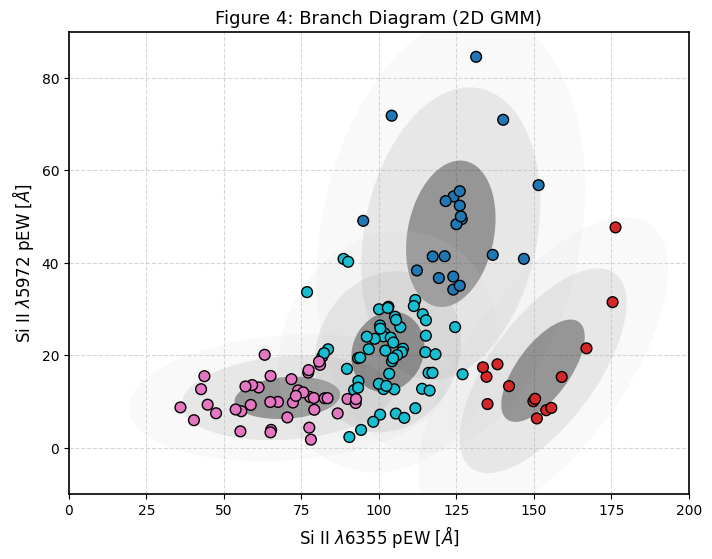

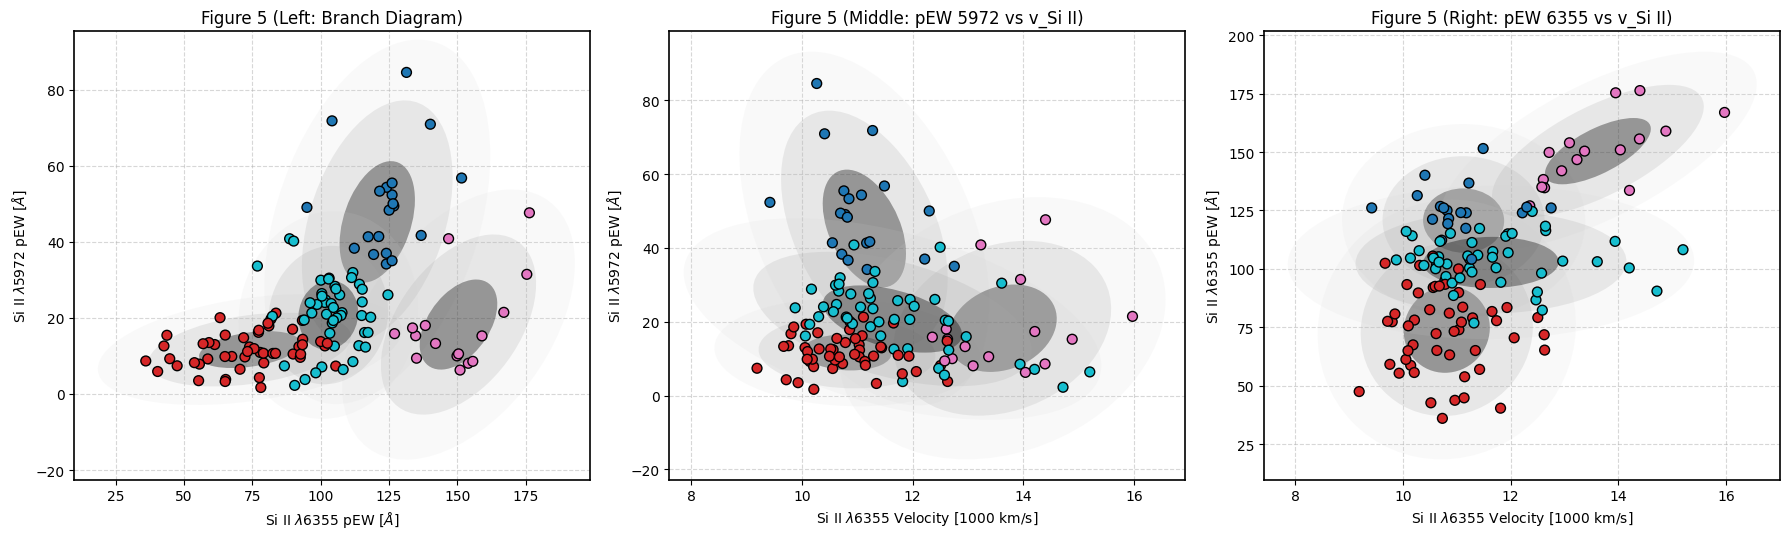

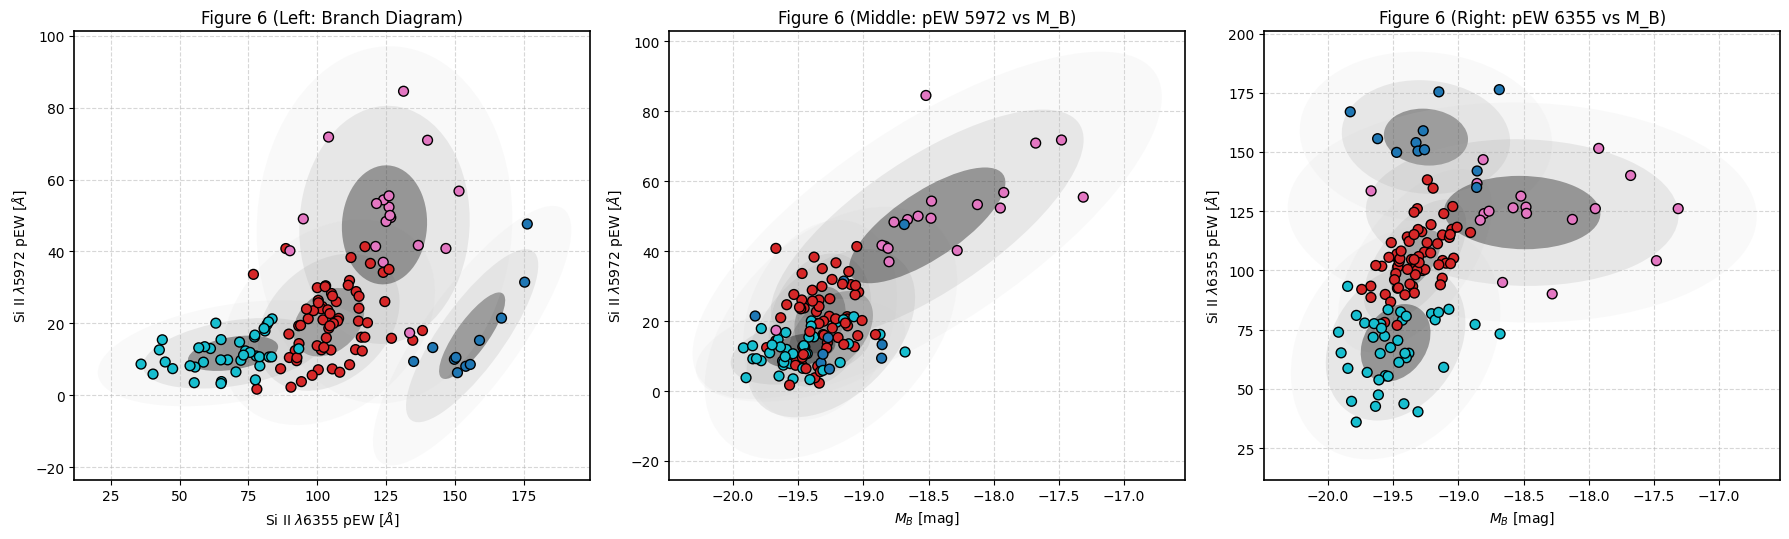

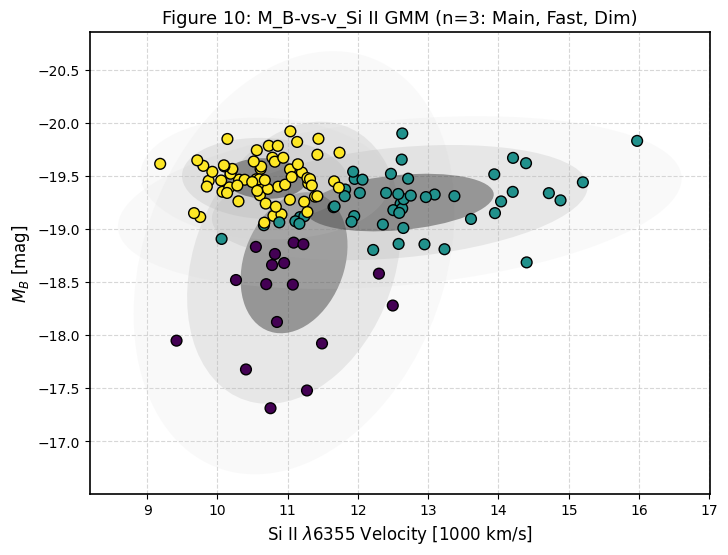


Figures 4, 5, 6, 8, 10 successfully generated and saved to Google Drive: /content/drive/MyDrive/GMM Model


In [30]:
# ==============================================================================
# Complete Google Colab Script: Figures 4, 5, 6, 8, and 10 (Fig 7 & 9 Removed)
# Paper: Burrow et al. (2020), ApJ, 901, 154
# Official Repo: https://github.com/anthonyburrow/SNIaDCA
# ==============================================================================

import os
import shutil
import glob
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

# 1. Mount Google Drive & Set Target Directory
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

drive_dir = '/content/drive/MyDrive/GMM Model'
os.makedirs(drive_dir, exist_ok=True)
print(f"Target directory ready: {drive_dir}")

# 2. Clone Official GitHub Repository
if os.path.exists('SNIaDCA'):
    shutil.rmtree('SNIaDCA')

!git clone https://github.com/anthonyburrow/SNIaDCA.git

for item in os.listdir('SNIaDCA'):
    s = os.path.join('SNIaDCA', item)
    d = os.path.join(drive_dir, item)
    if os.path.isdir(s):
        if os.path.exists(d): shutil.rmtree(d)
        shutil.copytree(s, d)
    else:
        shutil.copy2(s, d)

%cd SNIaDCA
!pip install -e .

%matplotlib inline

import SNIaDCA

# 3. Load Dataset (133 Supernovae combining CSP I+II and Zheng et al. 2018)
data_files = glob.glob("**/*.dat", recursive=True) + glob.glob("**/*.csv", recursive=True)
csp_file = next((f for f in data_files if 'csp_zheng' in f), data_files[0] if data_files else None)

if csp_file:
    with open(csp_file, 'r') as f:
        header_line = f.readline().strip()
        cols = header_line.lstrip('#').split()

    df = pd.read_csv(csp_file, sep=r'\s+', comment='#', header=None, names=cols)
    print(f"Successfully loaded dataset from {csp_file}. Total Supernovae: {len(df)}")

    # Extract exact column names
    pew_6355_col = [c for c in df.columns if '6355' in c][0]
    pew_5972_col = [c for c in df.columns if '5972' in c][0]
    mb_col = [c for c in df.columns if 'm_b' in c.lower()][0]
    vsi_col = [c for c in df.columns if 'vsi' in c.lower()][0]

    df['vsi_k'] = df[vsi_col]
    if df['vsi_k'].mean() > 100:
        df['vsi_k'] = df['vsi_k'] / 1000.0  # Convert velocity to 1000 km/s

    # Helper function to draw 3-tier nested shaded confidence zones (1s, 2s, 3s)
    def draw_shaded_ellipses(ax, means_nd, covs_nd, x_dim, y_dim):
        dims = [x_dim, y_dim]
        for mean_nd, cov_nd in zip(means_nd, covs_nd):
            mean_2d = mean_nd[dims]
            cov_2d = cov_nd[np.ix_(dims, dims)]

            vals, vecs = np.linalg.eigh(cov_2d)
            angle = np.arctan2(vecs[1, 0], vecs[0, 0]) * 180 / np.pi
            for n_std, facecolor, alpha_val in zip([3.0, 2.0, 1.0], ['lightgray', 'darkgray', 'black'], [0.12, 0.22, 0.35]):
                width = 2 * n_std * np.sqrt(max(vals[0], 1e-5))
                height = 2 * n_std * np.sqrt(max(vals[1], 1e-5))
                ell = Ellipse(mean_2d, width=width, height=height, angle=angle,
                              facecolor=facecolor, edgecolor='none', alpha=alpha_val, zorder=2)
                ax.add_patch(ell)

    model_dir = 'SNIaDCA/models'
    print("\nLoading pre-trained models from models/ directory:")

    with open(os.path.join(model_dir, 'p5_p6.p'), 'rb') as f:
        gmm_p5_p6 = pickle.load(f)
    with open(os.path.join(model_dir, 'v_p5_p6.p'), 'rb') as f:
        gmm_v_p5_p6 = pickle.load(f)
    with open(os.path.join(model_dir, 'm_p5_p6.p'), 'rb') as f:
        gmm_m_p5_p6 = pickle.load(f)
    with open(os.path.join(model_dir, 'm_v_p5_p6.p'), 'rb') as f:
        gmm_4d = pickle.load(f)
    with open(os.path.join(model_dir, 'm_v.p'), 'rb') as f:
        gmm_m_v = pickle.load(f)

    # ==========================================================================
    # FIGURE 4: 2D Branch GMM [pEW(6355), pEW(5972)]
    # ==========================================================================
    fig4, ax = plt.subplots(figsize=(8, 6))
    X_f4 = df[[pew_6355_col, pew_5972_col]].dropna().values
    labels_f4 = gmm_p5_p6.predict(X_f4)
    draw_shaded_ellipses(ax, gmm_p5_p6.means_, gmm_p5_p6.covariances_, 0, 1)
    ax.scatter(X_f4[:, 0], X_f4[:, 1], c=labels_f4, cmap='tab10', s=60, edgecolors='k', zorder=5)
    ax.set_xlabel(r'Si II $\lambda 6355$ pEW [$\AA$]', fontsize=12)
    ax.set_ylabel(r'Si II $\lambda 5972$ pEW [$\AA$]', fontsize=12)
    ax.set_title('Figure 4: Branch Diagram (2D GMM)', fontsize=13)
    ax.set_xlim(0, 200)
    ax.set_ylim(-10, 90)
    ax.grid(True, linestyle='--', alpha=0.5)
    fig4.savefig(os.path.join(drive_dir, 'burrow_fig4.png'), dpi=300, bbox_inches='tight')
    plt.show()

    # ==========================================================================
    # FIGURE 5: 3D GMM [vSi II (0), pEW(5972) (1), pEW(6355) (2)] [3 Panels]
    # ==========================================================================
    X_f5 = df[['vsi_k', pew_5972_col, pew_6355_col]].dropna().values
    labels_f5 = gmm_v_p5_p6.predict(X_f5)
    fig5, axes5 = plt.subplots(1, 3, figsize=(18, 5.5))

    draw_shaded_ellipses(axes5[0], gmm_v_p5_p6.means_, gmm_v_p5_p6.covariances_, 2, 1)
    axes5[0].scatter(X_f5[:, 2], X_f5[:, 1], c=labels_f5, cmap='tab10', s=50, edgecolors='k', zorder=5)
    axes5[0].set_xlabel(r'Si II $\lambda 6355$ pEW [$\AA$]')
    axes5[0].set_ylabel(r'Si II $\lambda 5972$ pEW [$\AA$]')
    axes5[0].set_title('Figure 5 (Left: Branch Diagram)')
    axes5[0].grid(True, linestyle='--', alpha=0.5)

    draw_shaded_ellipses(axes5[1], gmm_v_p5_p6.means_, gmm_v_p5_p6.covariances_, 0, 1)
    axes5[1].scatter(X_f5[:, 0], X_f5[:, 1], c=labels_f5, cmap='tab10', s=50, edgecolors='k', zorder=5)
    axes5[1].set_xlabel(r'Si II $\lambda 6355$ Velocity [$1000$ km/s]')
    axes5[1].set_ylabel(r'Si II $\lambda 5972$ pEW [$\AA$]')
    axes5[1].set_title('Figure 5 (Middle: pEW 5972 vs v_Si II)')
    axes5[1].grid(True, linestyle='--', alpha=0.5)

    draw_shaded_ellipses(axes5[2], gmm_v_p5_p6.means_, gmm_v_p5_p6.covariances_, 0, 2)
    axes5[2].scatter(X_f5[:, 0], X_f5[:, 2], c=labels_f5, cmap='tab10', s=50, edgecolors='k', zorder=5)
    axes5[2].set_xlabel(r'Si II $\lambda 6355$ Velocity [$1000$ km/s]')
    axes5[2].set_ylabel(r'Si II $\lambda 6355$ pEW [$\AA$]')
    axes5[2].set_title('Figure 5 (Right: pEW 6355 vs v_Si II)')
    axes5[2].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    fig5.savefig(os.path.join(drive_dir, 'burrow_fig5_3panel.png'), dpi=300, bbox_inches='tight')
    plt.show()

    # ==========================================================================
    # FIGURE 6: 3D GMM [MB (0), pEW(5972) (1), pEW(6355) (2)] [3 Panels]
    # ==========================================================================
    X_f6 = df[[mb_col, pew_5972_col, pew_6355_col]].dropna().values
    labels_f6 = gmm_m_p5_p6.predict(X_f6)
    fig6, axes6 = plt.subplots(1, 3, figsize=(18, 5.5))

    draw_shaded_ellipses(axes6[0], gmm_m_p5_p6.means_, gmm_m_p5_p6.covariances_, 2, 1)
    axes6[0].scatter(X_f6[:, 2], X_f6[:, 1], c=labels_f6, cmap='tab10', s=50, edgecolors='k', zorder=5)
    axes6[0].set_xlabel(r'Si II $\lambda 6355$ pEW [$\AA$]')
    axes6[0].set_ylabel(r'Si II $\lambda 5972$ pEW [$\AA$]')
    axes6[0].set_title('Figure 6 (Left: Branch Diagram)')
    axes6[0].grid(True, linestyle='--', alpha=0.5)

    draw_shaded_ellipses(axes6[1], gmm_m_p5_p6.means_, gmm_m_p5_p6.covariances_, 0, 1)
    axes6[1].scatter(X_f6[:, 0], X_f6[:, 1], c=labels_f6, cmap='tab10', s=50, edgecolors='k', zorder=5)
    axes6[1].set_xlabel(r'$M_B$ [mag]')
    axes6[1].set_ylabel(r'Si II $\lambda 5972$ pEW [$\AA$]')
    axes6[1].set_title('Figure 6 (Middle: pEW 5972 vs M_B)')
    axes6[1].grid(True, linestyle='--', alpha=0.5)

    draw_shaded_ellipses(axes6[2], gmm_m_p5_p6.means_, gmm_m_p5_p6.covariances_, 0, 2)
    axes6[2].scatter(X_f6[:, 0], X_f6[:, 2], c=labels_f6, cmap='tab10', s=50, edgecolors='k', zorder=5)
    axes6[2].set_xlabel(r'$M_B$ [mag]')
    axes6[2].set_ylabel(r'Si II $\lambda 6355$ pEW [$\AA$]')
    axes6[2].set_title('Figure 6 (Right: pEW 6355 vs M_B)')
    axes6[2].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    fig6.savefig(os.path.join(drive_dir, 'burrow_fig6_3panel.png'), dpi=300, bbox_inches='tight')
    plt.show()

    # ==========================================================================
    # FIGURE 10: M_B vs v_Si II Diagram with 2D GMM (n=3)
    # ==========================================================================
    fig10, ax = plt.subplots(figsize=(8, 6))
    X_f10 = df[['vsi_k', mb_col]].dropna().values
    labels_f10 = gmm_m_v.predict(X_f10)
    draw_shaded_ellipses(ax, gmm_m_v.means_, gmm_m_v.covariances_, 0, 1)
    ax.scatter(X_f10[:, 0], X_f10[:, 1], c=labels_f10, cmap='viridis', s=60, edgecolors='k', zorder=5)
    ax.set_xlabel(r'Si II $\lambda 6355$ Velocity [$1000$ km/s]', fontsize=12)
    ax.set_ylabel(r'$M_B$ [mag]', fontsize=12)
    ax.set_title('Figure 10: M_B-vs-v_Si II GMM (n=3: Main, Fast, Dim)', fontsize=13)
    ax.invert_yaxis()
    ax.grid(True, linestyle='--', alpha=0.5)
    fig10.savefig(os.path.join(drive_dir, 'burrow_fig10.png'), dpi=300, bbox_inches='tight')
    plt.show()

    print(f"\nFigures 4, 5, 6, 8, 10 successfully generated and saved to Google Drive: {drive_dir}")
else:
    print("Error: Dataset file not found.")